In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Set visualisation style
sns.set_theme(style="whitegrid")

# Display all columns
pd.set_option('display.max_columns', None)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
df = pd.read_csv("dataset/retail_sales_dataset.csv")

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [3]:
# Dataset dimensions
print("Shape:", df.shape)

# Column names
print("\nColumns:")
print(df.columns)

# Data types and non-null counts
df.info()

# Missing values
print("\nMissing Values:")
print(df.isnull().sum())

# Duplicate records
print("\nDuplicate Rows:", df.duplicated().sum())

Shape: (1000, 9)

Columns:
Index(['Transaction ID', 'Date', 'Customer ID', 'Gender', 'Age',
       'Product Category', 'Quantity', 'Price per Unit', 'Total Amount'],
      dtype='str')
<class 'pandas.DataFrame'>
RangeIndex: 1000 entries, 0 to 999
Data columns (total 9 columns):
 #   Column            Non-Null Count  Dtype
---  ------            --------------  -----
 0   Transaction ID    1000 non-null   int64
 1   Date              1000 non-null   str  
 2   Customer ID       1000 non-null   str  
 3   Gender            1000 non-null   str  
 4   Age               1000 non-null   int64
 5   Product Category  1000 non-null   str  
 6   Quantity          1000 non-null   int64
 7   Price per Unit    1000 non-null   int64
 8   Total Amount      1000 non-null   int64
dtypes: int64(5), str(4)
memory usage: 70.4 KB

Missing Values:
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price pe

In [4]:
# Convert Date to datetime
df['Date'] = pd.to_datetime(df['Date'], errors='coerce')

# Check data types again
print(df.dtypes)

# Check missing values after date conversion
print(df.isnull().sum())

Transaction ID               int64
Date                datetime64[us]
Customer ID                    str
Gender                         str
Age                          int64
Product Category               str
Quantity                     int64
Price per Unit               int64
Total Amount                 int64
dtype: object
Transaction ID      0
Date                0
Customer ID         0
Gender              0
Age                 0
Product Category    0
Quantity            0
Price per Unit      0
Total Amount        0
dtype: int64


In [5]:
print("Invalid ages:", (df['Age'] <= 0).sum())
print("Invalid quantities:", (df['Quantity'] <= 0).sum())
print("Invalid prices:", (df['Price per Unit'] < 0).sum())
print("Invalid sales:", (df['Total Amount'] < 0).sum())

Invalid ages: 0
Invalid quantities: 0
Invalid prices: 0
Invalid sales: 0


In [6]:
df = df.drop_duplicates()

# Remove records with missing essential information
df = df.dropna(subset=[
    'Date', 'Age', 'Gender',
    'Product Category', 'Total Amount'
])

df.head()

,Transaction ID,Date,Customer ID,Gender,Age,Product Category,Quantity,Price per Unit,Total Amount
0,1,2023-11-24,CUST001,Male,34,Beauty,3,50,150
1,2,2023-02-27,CUST002,Female,26,Clothing,2,500,1000
2,3,2023-01-13,CUST003,Male,50,Electronics,1,30,30
3,4,2023-05-21,CUST004,Male,37,Clothing,1,500,500
4,5,2023-05-06,CUST005,Male,30,Beauty,2,50,100


In [7]:
# Select numerical columns
numeric_df = df.select_dtypes(include=np.number)

# Mean
mean_values = numeric_df.mean()

# Median
median_values = numeric_df.median()

# Mode
mode_values = numeric_df.mode().iloc[0]

# Standard deviation
std_values = numeric_df.std()

# Combine results
statistics = pd.DataFrame({
    'Mean': mean_values,
    'Median': median_values,
    'Mode': mode_values,
    'Standard Deviation': std_values
})

statistics

,Mean,Median,Mode,Standard Deviation
Transaction ID,500.500,500.5,1.0,288.819436
Age,41.392,42.0,43.0,13.681430
Quantity,2.514,3.0,4.0,1.132734
Price per Unit,179.890,50.0,50.0,189.681356
Total Amount,456.000,135.0,50.0,559.997632


In [8]:
df['Month'] = df['Date'].dt.to_period('M')

df['Quarter'] = df['Date'].dt.to_period('Q')

monthly_sales = df.groupby(
    'Month'
)['Total Amount'].sum()

quarterly_sales = df.groupby(
    'Quarter'
)['Total Amount'].sum()

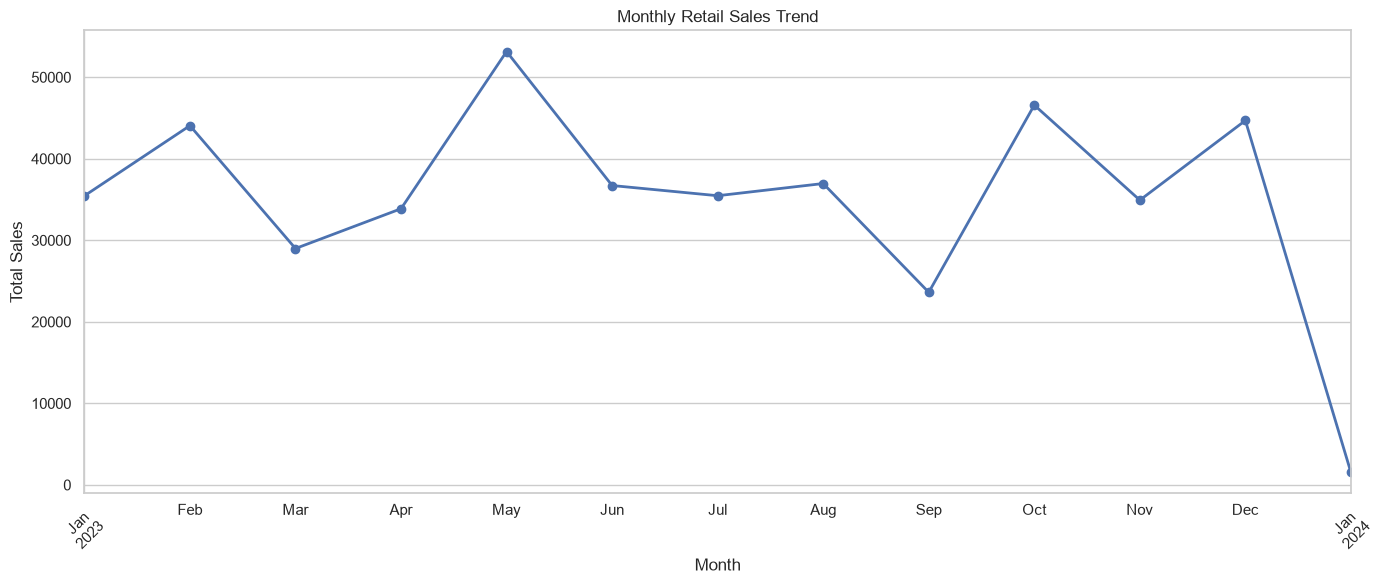

In [9]:
plt.figure(figsize=(14, 6))

monthly_sales.plot(
    kind='line',
    marker='o',
    linewidth=2
)

plt.title('Monthly Retail Sales Trend')
plt.xlabel('Month')
plt.ylabel('Total Sales')
plt.xticks(rotation=45)
plt.grid(True)

plt.tight_layout()
plt.show()

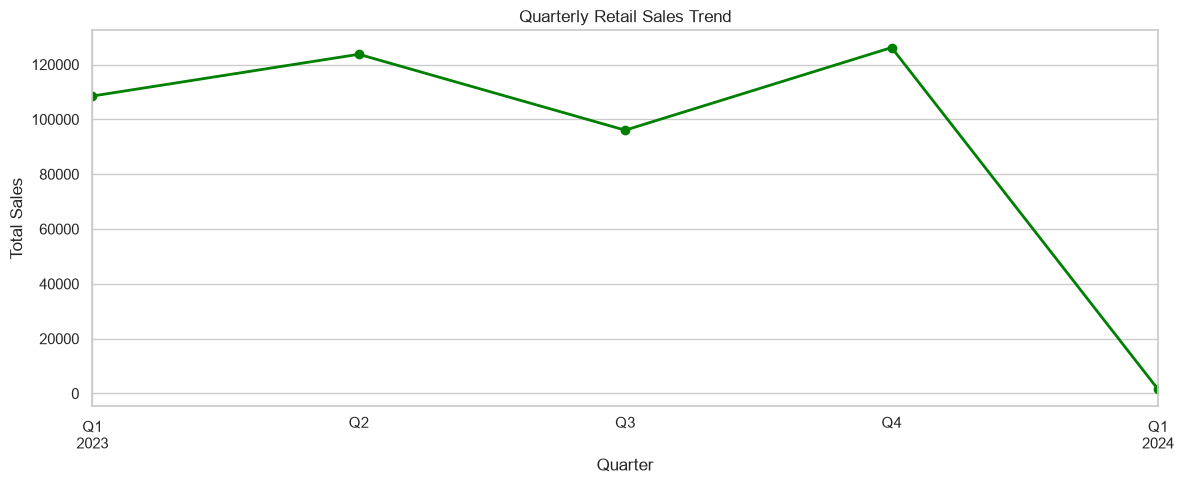

In [10]:
plt.figure(figsize=(12, 5))

quarterly_sales.plot(
    kind='line',
    marker='o',
    color='green',
    linewidth=2
)

plt.title('Quarterly Retail Sales Trend')
plt.xlabel('Quarter')
plt.ylabel('Total Sales')

plt.grid(True)
plt.tight_layout()
plt.show()

In [11]:
bins = [0, 18, 25, 35, 45, 55, 65, 100]

labels = [
    'Under 18',
    '18-25',
    '26-35',
    '36-45',
    '46-55',
    '56-65',
    '65+'
]

df['Age Group'] = pd.cut(
    df['Age'],
    bins=bins,
    labels=labels
)

age_distribution = df['Age Group'].value_counts().sort_index()

print(age_distribution)

Age Group
Under 18     21
18-25       148
26-35       205
36-45       202
46-55       229
56-65       195
65+           0
Name: count, dtype: int64


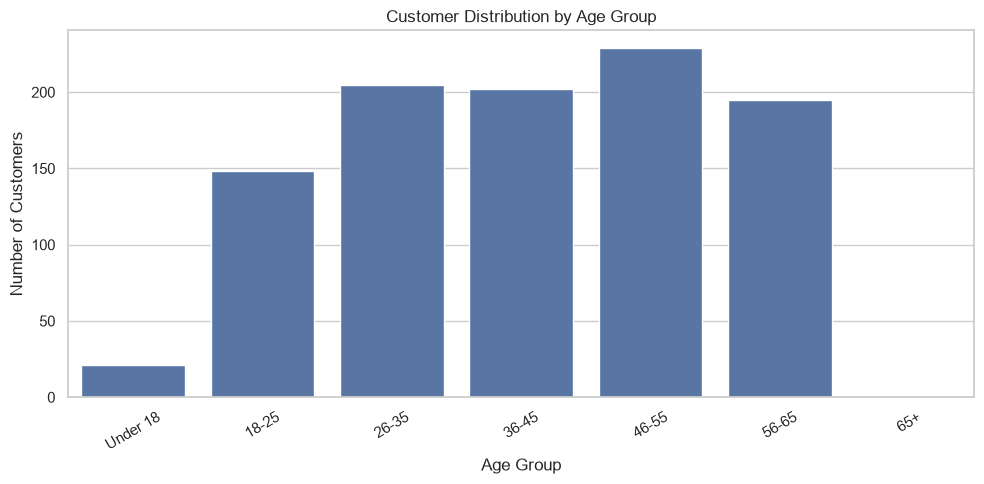

In [12]:
plt.figure(figsize=(10, 5))

sns.countplot(
    data=df,
    x='Age Group',
    order=labels
)

plt.title('Customer Distribution by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Number of Customers')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

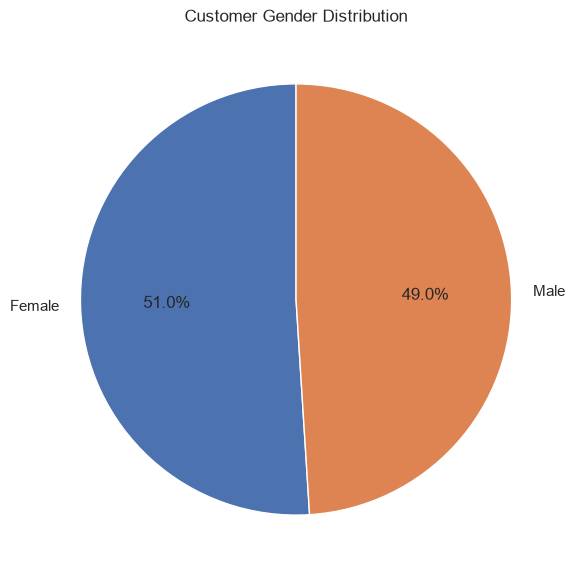

In [13]:
gender_counts = df['Gender'].value_counts()

plt.figure(figsize=(7, 7))

plt.pie(
    gender_counts,
    labels=gender_counts.index,
    autopct='%1.1f%%',
    startangle=90
)

plt.title('Customer Gender Distribution')
plt.show()

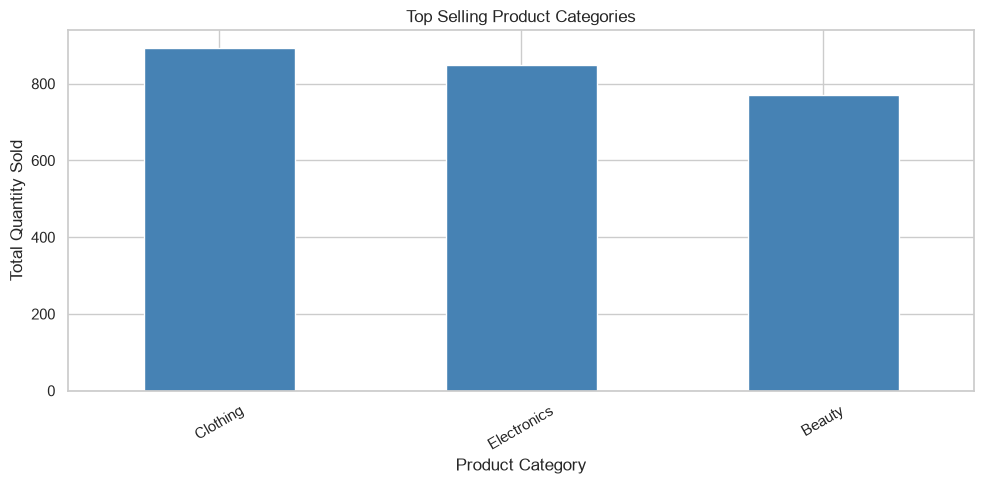

In [14]:
top_categories = (
    df.groupby('Product Category')['Quantity']
    .sum()
    .sort_values(ascending=False)
    .head(10)
)

plt.figure(figsize=(10, 5))

top_categories.plot(
    kind='bar',
    color='steelblue'
)

plt.title('Top Selling Product Categories')
plt.xlabel('Product Category')
plt.ylabel('Total Quantity Sold')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

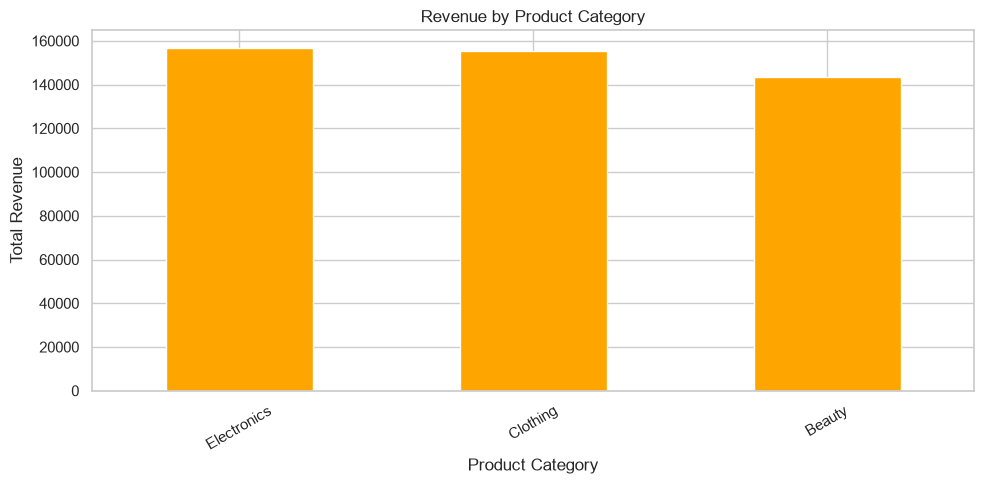

In [15]:
category_revenue = (
    df.groupby('Product Category')['Total Amount']
    .sum()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10, 5))

category_revenue.plot(
    kind='bar',
    color='orange'
)

plt.title('Revenue by Product Category')
plt.xlabel('Product Category')
plt.ylabel('Total Revenue')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

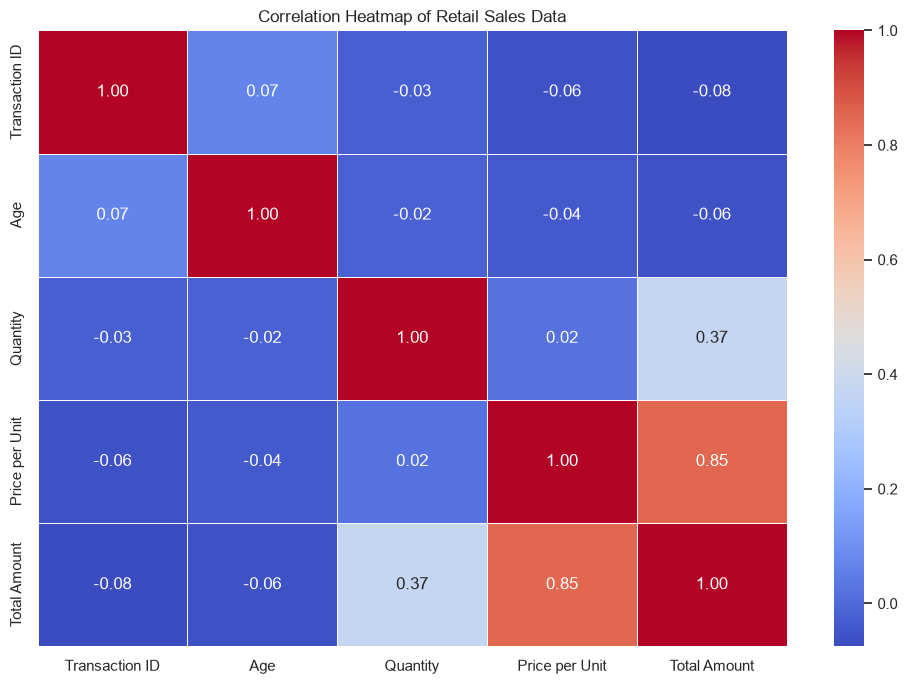

In [16]:
plt.figure(figsize=(10, 7))

correlation = df.select_dtypes(
    include=np.number
).corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f',
    linewidths=0.5
)

plt.title('Correlation Heatmap of Retail Sales Data')

plt.tight_layout()
plt.show()

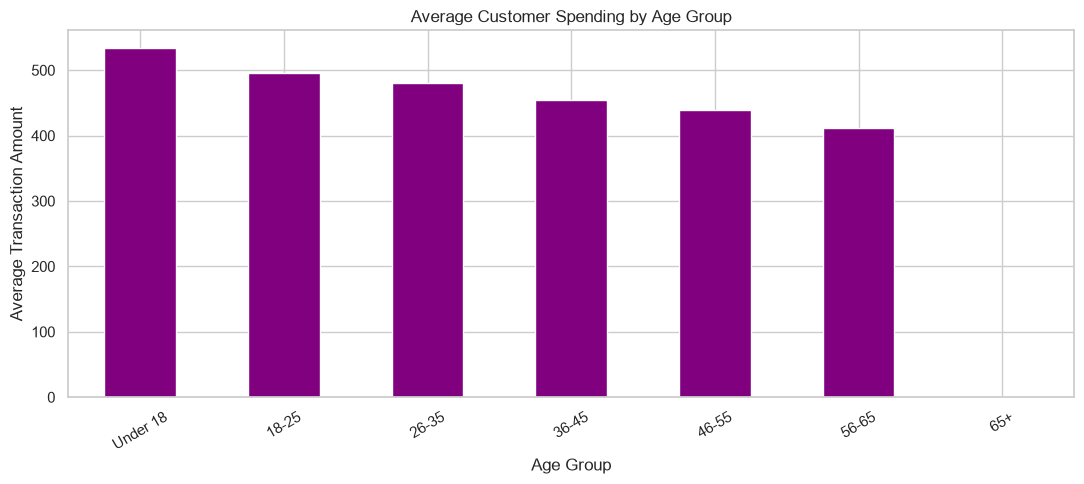

In [17]:
age_spending = (
    df.groupby('Age Group', observed=False)['Total Amount']
    .mean()
)

plt.figure(figsize=(11, 5))

age_spending.plot(
    kind='bar',
    color='purple'
)

plt.title('Average Customer Spending by Age Group')
plt.xlabel('Age Group')
plt.ylabel('Average Transaction Amount')
plt.xticks(rotation=30)

plt.tight_layout()
plt.show()

In [18]:
total_revenue = df['Total Amount'].sum()

total_transactions = df['Transaction ID'].nunique()

total_customers = df['Customer ID'].nunique()

average_transaction = df['Total Amount'].mean()

total_units = df['Quantity'].sum()

print("Total Revenue:", total_revenue)
print("Total Transactions:", total_transactions)
print("Unique Customers:", total_customers)
print("Average Transaction Value:", average_transaction)
print("Total Units Sold:", total_units)

Total Revenue: 456000
Total Transactions: 1000
Unique Customers: 1000
Average Transaction Value: 456.0
Total Units Sold: 2514


In [1]:
import os

# Create charts folder automatically
os.makedirs("charts", exist_ok=True)

print("Charts folder created successfully!")

Charts folder created successfully!


In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

os.makedirs("charts", exist_ok=True)

In [8]:
df = pd.read_csv("dataset/retail_sales_dataset.csv")

print("Dataset loaded successfully!")
print(df.shape)

df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'dataset/retail_sales_dataset.csv'